In [97]:
GROUP_ID = 'Group3'
ALGORITHM = ''
PUZZLE_TYPE = 'easy'
PUZZLE_PATH = 'Puzzles/Puzzles/Easy-P1.txt'

In [3]:
import random
import math
import matplotlib.pyplot as plt

class SudokuBoard:
    def __init__(self, grid, puzzle_type, puzzle_num):
        self.grid: list[list[int|str]] = [row[:] for row in grid]
        self.puzzle_type = puzzle_type
        self.puzzle_num = puzzle_num
    
    def printBoard(self):
        for row in self.grid:
            print(" ".join(str(x) for x in row))

In [4]:
### Board Functions

def read_board(BOARD_PATH):
    with open(BOARD_PATH, "r", encoding="utf-8-sig") as file:
        board = []
        for raw in file:
            line = raw.strip()
            #print(type(line)) #<class 'str'>
            cells = [c.strip() for c in line.split(',')]
#            print(cells)
            board.append(cells)
#        print(board)
    return board

def row_check(BOARD, row_num, count_zero):
    numbers = []
    duplicate_numbers = []
    num_empty = 0
    for i in BOARD[row_num]:
        if i == "?" and count_zero == True:
            num_empty += 1 
        if i != "?":
            if i in numbers:
                duplicate_numbers.append(i)
            else:
                numbers.append(i)
    if len(duplicate_numbers) > 0 or num_empty != 0:
        return False #Row constraint Failed
    else:
        return True #Row constraint passed

def col_check(BOARD, col_num, count_zero):
    column = [row[col_num] for row in BOARD]
    numbers = []
    duplicate_numbers = []
    num_empty = 0
    for i in column:
        if i == "?" and count_zero == True:
            num_empty += 1 
        if i != "?":
            if i in numbers:
                duplicate_numbers.append(i)
            else:
                numbers.append(i)
    if len(duplicate_numbers) > 0 or num_empty != 0:
        return False #Col constraint Failed
    else:
        return True #Col constraint passed
        
def block_check(BOARD, block_num, count_zero):
    #1 is top left, 2 is top center , 3 is top right
    start_row = ((block_num - 1) // 3) * 3
    start_col = ((block_num - 1) // 3) * 3

    block = []
    for r in range(start_row, start_row + 3):
        for c in range(start_col, start_col + 3):
            block.append(BOARD[r][c])
    numbers = []
    duplicate_numbers = []
    num_empty = 0
    for i in block:
        if i == "?" and count_zero == True:
            num_empty += 1 
        if i != "?":
            if i in numbers:
                duplicate_numbers.append(i)
            else:
                numbers.append(i)
    if len(duplicate_numbers) > 0 or num_empty != 0:
        return False #Block constraint Failed
    else:
        return True #Block constraint passed

def checkIfSolved(board):
    for i in range(9):
        if row_check(board, i, True) == False:
            print(f'Rowcheck {i} failed')
            return False
        if col_check(board, i, True) == False: 
            print(f'Column Check {i} failed')
            return False
        if block_check(board, i+1, True) == False: 
            print(f'Block Check {i} failed')
            return False
    return True

def save_solution(board, algorithm):
    # build filename
    filename = f"Group03_{algorithm}_{board.puzzle_type}puzzle{board.puzzle_num}.txt"

    # open and write
    with open(filename, "w") as f:
        for row in board.grid:
            # join row elements with commas
            line = ",".join(str(cell) for cell in row)
            f.write(line + "\n")

    print(f"Solution saved to {filename}")


In [78]:
### CSP Helper Functions

def emptyValues(BOARD):
    variables = []
    for row in range(9):
        for col in range(9):
            if BOARD[row][col] == "?":
                variables.append((row, col))
    return variables

def buildCSP(BOARD):
    #variables = empty cells
    #domain = all values for one cell
    #neighbors
    variables = emptyValues(BOARD)
    domain = {v: set(availableValues(BOARD, v[0], v[1])) for v in variables}  # sets of '1'..'9'
    Vset = set(variables)
    neighbors = {}
    for (r, c) in variables:
        row, col, box = neighborCoords(r, c)  # each is a set of (rr,cc)
        neighbors[(r, c)] = (row | col | box) & Vset  # keep only empties
    
    return variables, domain, neighbors


def availableValues(BOARD, cell_row, cell_col):
    domain = ['1', '2', '3', '4', '5', '6', '7', '8', '9']
    removed_domain = []
    col_vals = [BOARD[i][cell_col] for i in range(9)]
    start_row = ((cell_row) // 3) * 3
    start_col = ((cell_col) // 3) * 3
    block = []
    for r in range(start_row, start_row + 3):
        for c in range(start_col, start_col + 3):
            block.append(BOARD[r][c])
    for value in domain:
        if value in BOARD[cell_row]:
            removed_domain.append(value)
        if value in col_vals:
            removed_domain.append(value)
        if value in block:
            removed_domain.append(value)
    allowedValues = list(set(domain) - set(removed_domain))
    return allowedValues

def matchValuesToUnknown(BOARD):
    value = 0
    available = []
    mappedValues = dict()
    zeroes = buildCSP(BOARD)
    while value < len(zeroes):
        mappedValues[zeroes[value]] = availableValues(BOARD, zeroes[value][0], zeroes[value][1])
        value += 1
    return mappedValues

def neighborCoords(cell_row, cell_col):
    row = {(cell_row, col_num) for col_num in range(9) if col_num != cell_col}
    col = {(row_num, cell_col) for row_num in range(9) if row_num != cell_row}
    row_block = (cell_row // 3) * 3
    col_block = (cell_col // 3) * 3
    box = {(row_num, col_num) for row_num in range(row_block, row_block+3) for col_num in range(col_block, col_block+3) if (row_num, col_num) != (cell_row, cell_col)}
    return row, col, box


def buildNeighborsMap(variables):
    V = set(variables)
    return {v: {u for u in peers_of(*v) if u in V} for v in V}

def selectMRV(variables, domain, neighbors, assign):
    U = [v for v in variables if v not in assign]
    if not U:
        return None
    # MRV
    min_size = min(len(domain[v]) for v in U)
    cand = [v for v in U if len(domain[v]) == min_size]
    if len(cand) == 1:
        return cand[0]
    return max(cand, key=lambda v: sum(1 for n in neighbors[v] if n not in assign))
    #https://stackoverflow.com/questions/18296755/python-max-function-using-key-and-lambda-expression


def order_values_LCV(v, D, N, assign):
    if not D[v]:
        return []  
    def cost(val):
        return sum(1 for n in N[v] if n not in assign and val in D[n])
    return sorted(D[v], key=cost)


In [6]:
### Backtracking

def goalFound(BOARD):
    #no ?
    return all(BOARD[r][c] != "?" for r in range(9) for c in range(9))

def deriveAssignment(BOARD):
    return {(r, c): BOARD[r][c]
            for r in range(9) for c in range(9)
            if BOARD[r][c] != "?"}

def checkPlacement(BOARD, r, c, val):
    return val in availableValues(BOARD, r, c)

def backtrack(BOARD, counters):
    # Stop when solved
    if goalFound(BOARD):
        return True
    V, D, N = buildCSP(BOARD)
    assign = deriveAssignment(BOARD)
    if not V:
        return False
    var = selectMRV(V, D, N, assign)
    r, c = var
    for val in order_values_LCV(var, D, N, assign):
        if not checkPlacement(BOARD, r, c, val):
            continue
        BOARD[r][c] = val
        counters["nodes"] += 1
        if backtrack(BOARD, counters):
            return True
        BOARD[r][c] = "?"
        counters["backtracks"] += 1
    return False

def solveDFSbacktracking(board):
    BOARD = board.grid
    B = [row[:] for row in BOARD]
    counters = {"nodes": 0, "backtracks": 0}
    ok = backtrack(B, counters)
    if ok:
        board.grid = B
        save_solution(
            board,
            algorithm="bt"
        )
    return (B if ok else None), counters

In [7]:
### Forward checking

#Forward Checking
def forwardChecking(BOARD, V, D, N, counters, assign):
    if goalFound(BOARD):
        return True
    var = selectMRV(V, D, N, assign)
    r, c = var
    for val in order_values_LCV(var, D, N, assign):
        if val not in D[var]:
            continue
        if not checkPlacement(BOARD, r, c, val):
            continue
            
        # try assignment
        BOARD[r][c] = val
        assign[var] = val
        counters["nodes"] += 1

        ok, pruned = forwardPrune(var, val, D, N, assign)
        if ok and forwardChecking(BOARD, V, D, N, counters, assign):
            return True

        # undo
        reversePrune(pruned, D)
        del assign[var]
        BOARD[r][c] = "?"
        counters["backtracks"] += 1

    return False


def forwardPrune(variable, value, domain, neighbors, assign):
    prunedList = []
    for n in neighbors[variable]:
        if value in domain[n]:
            domain[n].remove(value)
            prunedList.append((n, value))
            if not domain[n]:     # domain completely gone
                return False, prunedList
    return True, prunedList

def reversePrune(prunedList, domain):
    for num, value in prunedList:
        domain[num].add(value)

def solveDFSforwardChecking(board):
    BOARD = board.grid
    B = [row[:] for row in BOARD]
    V, D, N = buildCSP(B)
    # use sets for pruning
    D = {v: set(D[v]) for v in V}
    assign = deriveAssignment(B)
    # seed assigned cells' domains
    for v, val in assign.items():
        D[v] = {val}
    counters = {"nodes": 0, "backtracks": 0}
    ok = forwardChecking(B, V, D, N, counters, assign)
    if ok:
        board.grid = B
        save_solution(
            board,
            algorithm="fc"
        )
    return (B if ok else None), counters

In [8]:
### Arc-3 Consistency

#arc-consistency algorithm AC-3
def revise(domain, Xi, Xj):
    revised = False
    removed = []
    for a in list(domain[Xi]):               
        if all(b == a for b in domain[Xj]):  
            domain[Xi].remove(a)
            removed.append(a)
            revised = True
    return revised, removed


def ac3(domain, neighbors, initial_queue=None):
    # build queue as list of (Xi, Xj) pairs
    if initial_queue is None:
        queue = [(Xi, Xj) for Xi in domain for Xj in neighbors[Xi]]
    else:
        queue = list(initial_queue)

    pruned = []
    while len(queue) > 0:
        Xi, Xj = queue.pop(0) 
        changed, removed_vals = revise(domain, Xi, Xj)
        if changed:
            for v in removed_vals:
                pruned.append((Xi, v))
            if not domain[Xi]:       # domain all gone
                return False, pruned
            for Xk in neighbors[Xi]:
                if Xk != Xj:
                    queue.append((Xk, Xi))
    return True, pruned

def undo_ac3(pruned, D):
    for var, val in pruned:
        D[var].add(val)

def backtrack_ac3(BOARD, V, D, N, counters, assign):
    # success check
    if goalFound(BOARD):
        return True

    var = selectMRV(V, D, N, assign)
    r, c = var
    for val in order_values_LCV(var, D, N, assign):
        if val not in D[var]:
            continue
        if not checkPlacement(BOARD, r, c, val):
            continue
        saved_domain = D[var].copy()
        D[var] = {val}
        BOARD[r][c] = val
        assign[var] = val
        counters["nodes"] += 1

        init_q = [(n, var) for n in N[var] if n not in assign]
        ok, pruned_log = ac3(D, N, initial_queue=init_q)

        if ok and backtrack_ac3(BOARD, V, D, N, counters, assign):
            return True
        undo_ac3(pruned_log, D)
        D[var] = saved_domain
        del assign[var]
        BOARD[r][c] = "?"
        counters["backtracks"] += 1
    return False

def solveDFSac3(board):
    BOARD = board.grid
    B = [row[:] for row in BOARD]
    V, D, N = buildCSP(B)
    D = {v: set(D[v]) for v in V}
    assign = deriveAssignment(B)
    for v, val in assign.items():
        D[v] = {val}
    counters = {"nodes": 0, "backtracks": 0}
    ok = backtrack_ac3(B, V, D, N, counters, assign)
    if ok:
        board.grid = B
        save_solution(
            board,
            algorithm="ac3"
        )
    return (B if ok else None), counters


In [9]:
### State Space Search Helper Funcions

def fill_board_randomly(board):
    b = [row[:] for row in board]
    for r in range(9):
        known = {b[r][c] for c in range(9) if b[r][c] != "?"}
        missing = [str(d) for d in range(1, 10) if str(d) not in known]
        random.shuffle(missing)
        missing_index = 0
        for c in range(9):
            if b[r][c] == "?":
                b[r][c] = missing[missing_index]
                missing_index += 1
    return b

def fitness(board):
    conflicts = 0
    for c in range(9):
        col = [board[r][c] for r in range(9)]
        for v in set(col):
            if v != "?":
                conflicts += col.count(v) - 1
    for br in range(0, 9, 3):
        for bc in range(0, 9, 3):
            block = [board[r][c] for r in range(br, br+3) for c in range(bc, bc+3)]
            for v in set(block):
                if v != "?":
                    conflicts += block.count(v) - 1
    return conflicts

In [10]:
### Simulated Annealing

def swap_two_in_row(board, fixed):
    r = random.randrange(9)
    not_fixed = [c for c in range(9) if (r, c) not in fixed]
    if len(not_fixed) < 2:
        return board
    cell1, cell2 = random.sample(not_fixed, 2)
    new_board = [row[:] for row in board]
    new_board[r][cell1], new_board[r][cell2] = new_board[r][cell2], new_board[r][cell1]
    return new_board


def plot_sa_learning_curve(sa_counters):
    history = sa_counters["fitness_history"]

    plt.figure(figsize=(10, 5))
    plt.plot(history, label="SA")
    plt.xlabel("Iteration")
    plt.ylabel("Best Fitness")
    plt.title("Simulated Annealing Fitness Over Iterations")
    plt.legend()
    plt.grid(True)
    plt.show()

def solve_simulated_anealing(board_obj, iterations=200000, init_temp=1.0, cooling_rate=0.9995, stagnation_limit=20000):

    board = board_obj.grid

    fixed = {(r, c) for r in range(9) for c in range(9) if board[r][c] != "?"}
    current = fill_board_randomly(board)
    cur_fit = fitness(current)
    best = [row[:] for row in current]
    best_fit = cur_fit
    temp = init_temp
    stagnation = 0

    counters_print = {"iters": 0, "best_fit": best_fit, "fitness_history": [cur_fit]}

    for it in range(iterations):
        counters_print["iters"] = it
        if best_fit == 0:
            break

        # Generate neighbor without modifying current
        new_board = swap_two_in_row(current, fixed)
        new_fit = fitness(new_board)
        delta = new_fit - cur_fit

        accept = False
        if delta <= 0:
            accept = True
        elif random.random() < math.exp(-delta / max(temp, 1e-12)):
            accept = True

        if accept:
            current = fill_board_randomly(board)
            cur_fit = fitness(current)
            if new_fit < best_fit:
                best_fit = new_fit
                best = [row[:] for row in new_board]
                stagnation = 0
        else:
            stagnation += 1

        temp = temp * cooling_rate
        counters_print["fitness_history"].append(best_fit)

        if stagnation > stagnation_limit:
            current = fill_board_randomly(board)
            cur_fit = fitness(current)
            temp = init_temp
            stagnation = 0

    counters_print["best fit"] = best_fit
    best_obj = SudokuBoard(best, board_obj.puzzle_type, board_obj.puzzle_num)
    save_solution(best_obj, algorithm="sa")
    best_obj.printBoard()
    checkIfSolved(best_obj.grid)
    plot_sa_learning_curve(counters_print)

In [11]:
### Genetic Algorithm

def ga_tournament(pop, fits, tournament_size):
    indices = random.sample(range(len(pop)), tournament_size)
    indices.sort(key=lambda i: fits[i])
    return pop[indices[0]]

def ga_crossover(p1, p2):
    child = []
    for r in range(9):
        if random.random() < 0.5:
            child.append(p1[r][:])
        else:
            child.append(p2[r][:])
    return child

def ga_mutate(child, fixed, rate):
    for r in range(9):
        if random.random() < rate:
            not_fixed = [c for c in range(9) if (r, c) not in fixed]
            if len(not_fixed) >= 2:
                cell1, cell2 = random.sample(not_fixed, 2)
                child[r][cell1], child[r][cell2] = child[r][cell2], child[r][cell1]
    return child

def plot_ga_learning_curve(data):
    history = data["fitness history"]

    plt.plot(history)
    plt.xlabel("Generation")
    plt.ylabel("Best Fitness")
    plt.title("GA Fitness Over Generations")
    plt.grid(True)
    plt.show()

def solve_genetic_algorithm(board_obj, pop_size=200, generations=2000, mutation_rate=0.4, tournament_size=3, elite=4):

    board = board_obj.grid

    fixed = {(r, c) for r in range(9) for c in range(9) if board[r][c] != '?'}
    population = [fill_board_randomly(board) for _ in range(pop_size)]
    fits = [fitness(individual) for individual in population]

    best_index = min(range(pop_size), key=lambda i: fits[i])
    best = [row[:] for row in population[best_index]]
    best_fit = fits[best_index]

    counters_print = {"gen": 0, "best fit": best_fit, "fitness history": [best_fit]}

    for gen in range(generations):
        counters_print["gen"] = gen
        if best_fit == 0:
            break

        index_sorted = sorted(range(pop_size), key=lambda i: fits[i])
        new_pop = [[row[:] for row in population[i]] for i in index_sorted[:elite]] # keep fittest
        for e in range(1, elite):
            new_pop.append([row[:] for row in population[index_sorted[e]]])

        while len(new_pop) < pop_size:
            parent1 = ga_tournament(population, fits, tournament_size)
            parent2 = ga_tournament(population, fits, tournament_size)

            child = ga_crossover(parent1, parent2)

            child_mutate = ga_mutate(child, fixed, mutation_rate)

            new_pop.append(child_mutate)

        population = new_pop
        fits = [fitness(individual) for individual in population]
        best_index = min(range(pop_size), key=lambda i: fits[i])
        if fits[best_index] < best_fit:
            best_fit = fits[best_index]
            best = [row[:] for row in population[best_index]]
        
        counters_print["fitness history"].append(best_fit)

    best_obj = SudokuBoard(best, board_obj.puzzle_type, board_obj.puzzle_num)
    save_solution(best_obj, algorithm="ga")
    best_obj.printBoard()
    checkIfSolved(best_obj.grid)
    plot_ga_learning_curve(counters_print)

In [88]:
### Example run

#original_board = SudokuBoard(read_board("/../Users/Grant M Frandsen/Desktop/VS Code Projects/CSCI 446/Puzzles/Puzzles/Easy-P1.txt"))

original_board = SudokuBoard(read_board(PUZZLE_PATH), PUZZLE_TYPE, 1)

original_board.printBoard()
solved_board = [
    [5, 3, 4, 6, 7, 8, 9, 1, 2],
    [6, 7, 2, 1, 9, 5, 3, 4, 8],
    [1, 9, 8, 3, 4, 2, 5, 6, 7],
    [8, 5, 9, 7, 6, 1, 4, 2, 3],
    [4, 2, 6, 8, 5, 3, 7, 9, 1],
    [7, 1, 3, 9, 2, 4, 8, 5, 6],
    [9, 6, 1, 5, 3, 7, 2, 8, 4],
    [2, 8, 7, 4, 1, 9, 6, 3, 5],
    [3, 4, 5, 2, 8, 6, 1, 7, 9]
]
checkIfSolved(original_board.grid)
#checkIfSolved(solved_board)

? ? 8 ? 5 6 ? ? ?
7 ? 4 ? ? ? 6 1 9
? ? ? ? ? ? 8 5 ?
6 ? 7 ? 2 9 5 ? ?
? ? 9 ? 6 ? 1 ? ?
? ? 2 3 1 ? 9 ? 4
? 3 5 ? ? ? ? ? ?
4 2 1 ? ? ? 3 ? 6
? ? ? 8 3 ? 4 ? ?
Rowcheck 0 failed


False

In [93]:
#print(type(buildCSP(original_board.grid)[0][0]))
original_board = SudokuBoard(read_board(PUZZLE_PATH), PUZZLE_TYPE, 1)
solveDFSbacktracking(original_board)

#I solved for:
#1,9,8,7,5,6,2,4,3
#7,5,4,2,8,3,6,1,9
#2,6,3,1,9,4,8,5,7
#6,1,7,4,2,9,5,3,8
#3,4,9,5,6,8,1,7,2
#5,8,2,3,1,7,9,6,4
#8,3,5,6,4,2,7,9,1
#4,2,1,9,7,5,3,8,6
#9,7,6,8,3,1,4,2,5

Solution saved to Group03_bt_easypuzzle1.txt


([['1', '9', '8', '7', '5', '6', '2', '4', '3'],
  ['7', '5', '4', '2', '8', '3', '6', '1', '9'],
  ['2', '6', '3', '1', '9', '4', '8', '5', '7'],
  ['6', '1', '7', '4', '2', '9', '5', '3', '8'],
  ['3', '4', '9', '5', '6', '8', '1', '7', '2'],
  ['5', '8', '2', '3', '1', '7', '9', '6', '4'],
  ['8', '3', '5', '6', '4', '2', '7', '9', '1'],
  ['4', '2', '1', '9', '7', '5', '3', '8', '6'],
  ['9', '7', '6', '8', '3', '1', '4', '2', '5']],
 {'nodes': 48, 'backtracks': 0})

In [94]:
solveDFSforwardChecking(original_board)

Solution saved to Group03_fc_easypuzzle1.txt


([['1', '9', '8', '7', '5', '6', '2', '4', '3'],
  ['7', '5', '4', '2', '8', '3', '6', '1', '9'],
  ['2', '6', '3', '1', '9', '4', '8', '5', '7'],
  ['6', '1', '7', '4', '2', '9', '5', '3', '8'],
  ['3', '4', '9', '5', '6', '8', '1', '7', '2'],
  ['5', '8', '2', '3', '1', '7', '9', '6', '4'],
  ['8', '3', '5', '6', '4', '2', '7', '9', '1'],
  ['4', '2', '1', '9', '7', '5', '3', '8', '6'],
  ['9', '7', '6', '8', '3', '1', '4', '2', '5']],
 {'nodes': 0, 'backtracks': 0})

In [95]:
solveDFSac3(original_board)

Solution saved to Group03_ac3_easypuzzle1.txt


([['1', '9', '8', '7', '5', '6', '2', '4', '3'],
  ['7', '5', '4', '2', '8', '3', '6', '1', '9'],
  ['2', '6', '3', '1', '9', '4', '8', '5', '7'],
  ['6', '1', '7', '4', '2', '9', '5', '3', '8'],
  ['3', '4', '9', '5', '6', '8', '1', '7', '2'],
  ['5', '8', '2', '3', '1', '7', '9', '6', '4'],
  ['8', '3', '5', '6', '4', '2', '7', '9', '1'],
  ['4', '2', '1', '9', '7', '5', '3', '8', '6'],
  ['9', '7', '6', '8', '3', '1', '4', '2', '5']],
 {'nodes': 0, 'backtracks': 0})

Solution saved to Group03_ga_easypuzzle1.txt
1 9 8 7 5 6 2 4 3
7 5 4 2 8 3 6 1 9
2 6 3 1 9 4 8 5 7
6 1 7 4 2 9 5 3 8
3 4 9 5 6 8 1 7 2
5 8 2 3 1 7 9 6 4
8 3 5 6 4 2 7 9 1
4 2 1 9 7 5 3 8 6
9 7 6 8 3 1 4 2 5


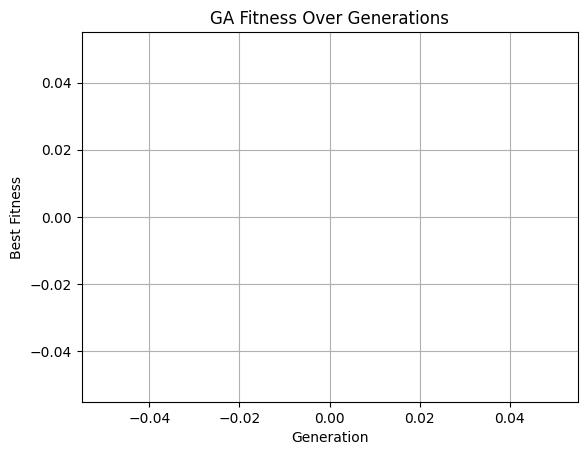

In [96]:
solve_genetic_algorithm(original_board)

Solution saved to Group03_sa_easypuzzle1.txt
2 5 3 9 1 4 6 8 7
6 8 9 3 7 2 5 1 4
7 1 4 8 5 6 2 9 3
1 4 2 6 9 7 8 3 5
5 3 8 4 2 1 9 7 6
9 6 7 5 3 8 4 2 1
8 7 1 2 6 5 3 4 9
3 2 6 7 4 9 1 5 8
4 9 5 1 8 3 7 6 2


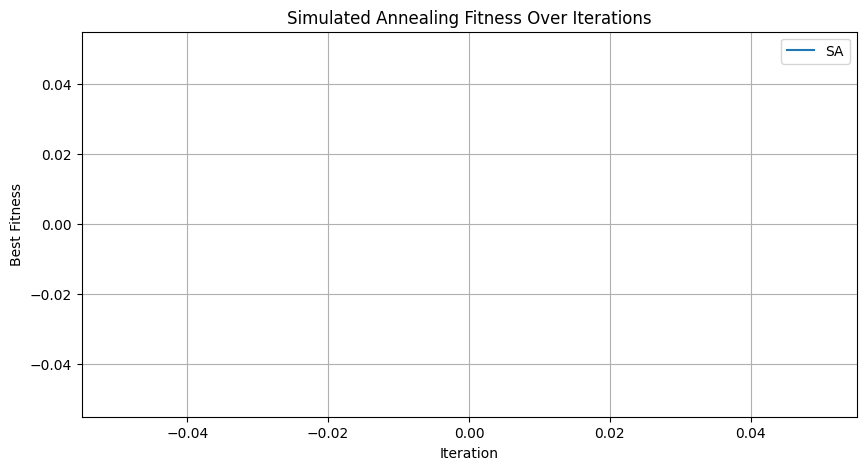

In [80]:
solve_simulated_anealing(original_board)

In [98]:
ga_board = SudokuBoard(read_board(PUZZLE_PATH), PUZZLE_TYPE, 1)
#solve_genetic_algorithm(ga_board)
solve_simulated_anealing(ga_board)
#I solved for:
#1,9,8,7,5,6,2,4,3
#7,5,4,2,8,3,6,1,9
#2,6,3,1,9,4,8,5,7
#6,1,7,4,2,9,5,3,8
#3,4,9,5,6,8,1,7,2
#5,8,2,3,1,7,9,6,4
#8,3,5,6,4,2,7,9,1
#4,2,1,9,7,5,3,8,6
#9,7,6,8,3,1,4,2,5

KeyboardInterrupt: 